# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [1]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [3]:
# Load the cleaned aviation data
df = pd.read_csv('cleaned_aviation_data.csv', low_memory=False)
df.head()

,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Latitude,Longitude,Airport.Code,Airport.Name,...,Total.Uninjured,Weather.Condition,Broad.phase.of.flight,Report.Status,Publication.Date,Total.Occupants,Fatal.Serious.Injuries,Fatal.Serious.Fraction,Aircraft.Destroyed,Aircraft.Type
0,20001213X30060,Accident,DCA87MA018B,1987-01-15,"KEARNS, UT",United States,NaN,NaN,NaN,NaN,...,NaN,VMC,MANEUVERING,Probable Cause,10-07-2019,NaN,NaN,NaN,1.0,MOONEY M-20C
1,20001213X30244,Accident,FTW87RA066,1987-02-14,"DURANGO, Mexico",Mexico,NaN,NaN,NaN,NaN,...,131.0,NaN,NaN,Foreign,07-02-1995,NaN,NaN,NaN,NaN,BOEING 707-323B
2,20001213X30820,Accident,SEA87LA072,1987-04-02,"JEAN, NV",United States,NaN,NaN,OL7,JEAN,...,1.0,VMC,LANDING,Probable Cause,10-04-2014,NaN,NaN,NaN,0.0,PIPER PA 16
3,20001213X25245,Accident,DCA88WA048,1988-03-27,"OXFORD, United Kingdom",United Kingdom,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,Foreign,NaN,NaN,NaN,NaN,1.0,PIPER PA-38
4,20001213X25425,Accident,CHI88FA091,1988-04-05,"ST. PAUL, MN",United States,NaN,NaN,NaN,NaN,...,5.0,IMC,CRUISE,Probable Cause,02-05-2011,NaN,NaN,NaN,0.0,BEECH B90


## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [4]:
# Separate small and large aircraft
# Create a column to classify aircraft size
df['Aircraft.Size'] = pd.NA

# Classify aircraft with fewer than 20 occupants as small
df.loc[df['Total.Occupants'] < 20, 'Aircraft.Size'] = 'Small'

# Classify aircraft with 20 or more occupants as large
df.loc[df['Total.Occupants'] >= 20, 'Aircraft.Size'] = 'Large'

# Count records in each group, including missing values
df['Aircraft.Size'].value_counts(dropna=False)

Aircraft.Size
Small    14479
<NA>      2598
Large      780
Name: count, dtype: int64

#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

In [5]:
# Calculate the mean injury fraction for each make and aircraft size
make_injury_rates = (
    df.dropna(subset=['Aircraft.Size', 'Fatal.Serious.Fraction', 'Make'])
    .groupby(['Aircraft.Size', 'Make'])['Fatal.Serious.Fraction']
    .mean()
    .reset_index()
)

In [6]:
# Select the 15 makes with the lowest mean injury fraction in each group
top_15_makes = (
    make_injury_rates
    .sort_values('Fatal.Serious.Fraction')
    .groupby('Aircraft.Size')
    .head(15)
)

top_15_makes

,Aircraft.Size,Make,Fatal.Serious.Fraction
7,Large,DEHAVILLAND,0.000000
5,Large,CESSNA,0.000000
10,Large,PIPER,0.000000
9,Large,MCDONNELL DOUGLAS,0.011661
6,Large,DE HAVILLAND,0.015152
4,Large,BOMBARDIER INC,0.028038
2,Large,BOEING,0.051341
8,Large,EMBRAER,0.056642
3,Large,BOMBARDIER,0.070406
0,Large,AIRBUS,0.080503


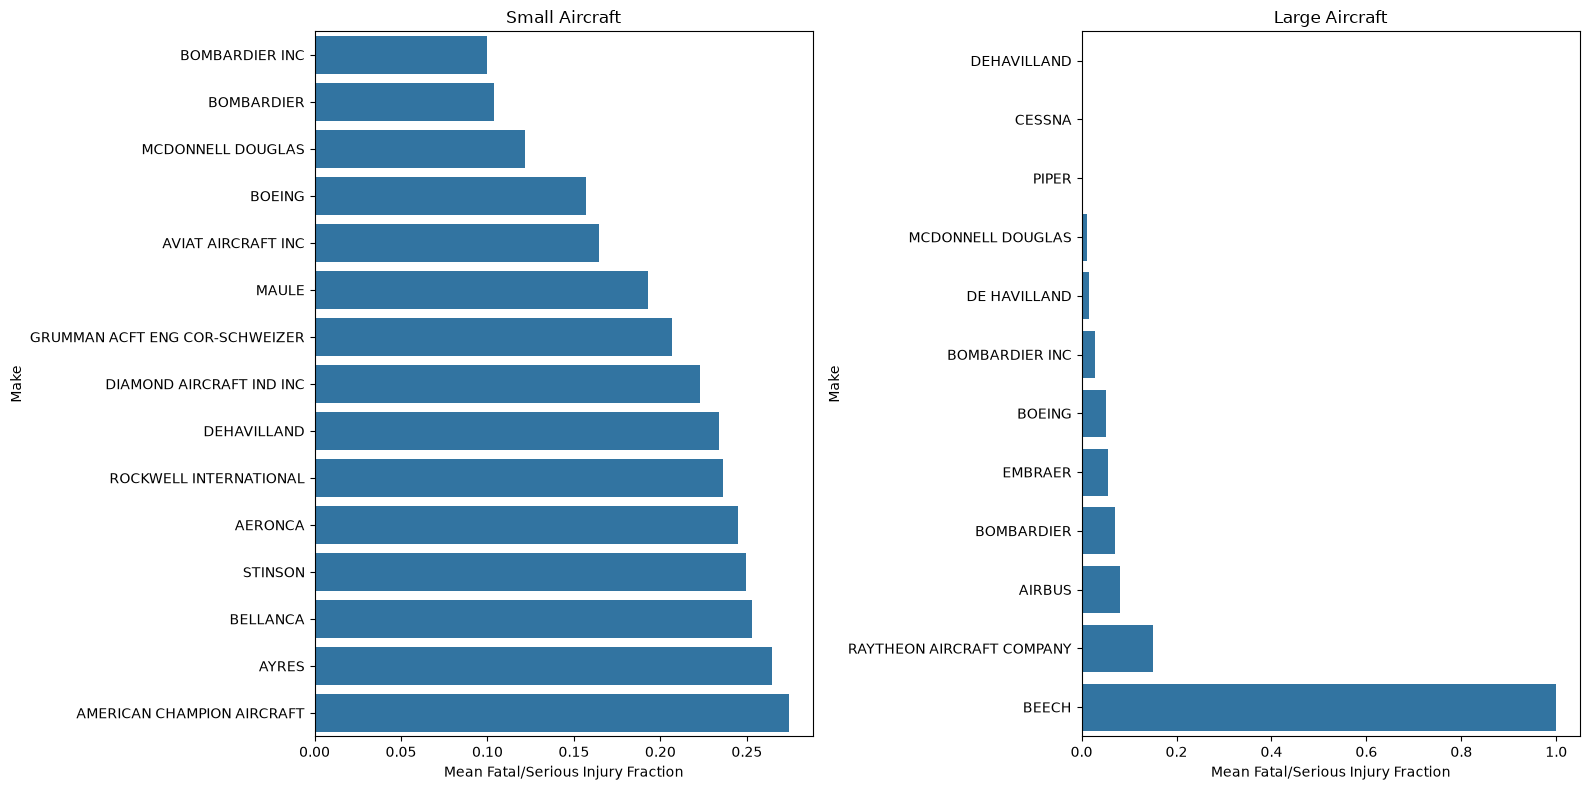

In [7]:
# Create side-by-side plots for small and large aircraft
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

for ax, size in zip(axes, ['Small', 'Large']):

    # Select the 15 makes for the current aircraft size
    plot_data = top_15_makes[
        top_15_makes['Aircraft.Size'] == size
    ].sort_values('Fatal.Serious.Fraction')

    # Plot the mean injury fraction for each make
    sns.barplot(
        data=plot_data,
        x='Fatal.Serious.Fraction',
        y='Make',
        ax=ax
    )

    ax.set_title(f'{size} Aircraft')
    ax.set_xlabel('Mean Fatal/Serious Injury Fraction')
    ax.set_ylabel('Make')

plt.tight_layout()
plt.show()

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

In [8]:
# Step 1: Select the 10 makes
# Calculate mean injury fraction for each small-aircraft make
small_make_rates = (
    df[df['Aircraft.Size'] == 'Small']
    .dropna(subset=['Make', 'Fatal.Serious.Fraction'])
    .groupby('Make')['Fatal.Serious.Fraction']
    .mean()
    .sort_values()
)

# Select the 10 makes with the lowest mean injury fractions
top_10_small_makes = small_make_rates.head(10)

# Display the selected makes and their means
top_10_small_makes

Make
BOMBARDIER INC                    0.100000
BOMBARDIER                        0.103846
MCDONNELL DOUGLAS                 0.121753
BOEING                            0.156968
AVIAT AIRCRAFT INC                0.164474
MAULE                             0.192593
GRUMMAN ACFT ENG COR-SCHWEIZER    0.206897
DIAMOND AIRCRAFT IND INC          0.222973
DEHAVILLAND                       0.234170
ROCKWELL INTERNATIONAL            0.236111
Name: Fatal.Serious.Fraction, dtype: float64

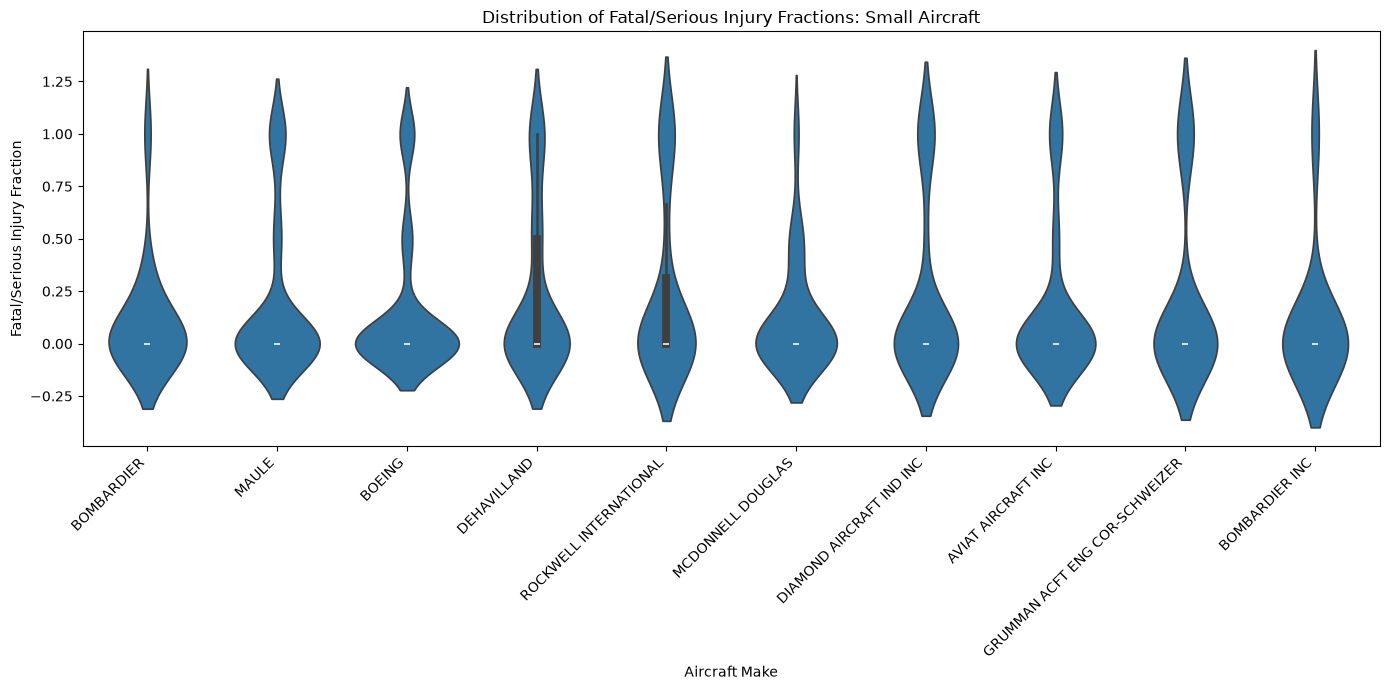

In [9]:
# Step 2: Create the violin pot
# Filter accident records for the 10 selected makes
small_plot_data = df[
    (df['Aircraft.Size'] == 'Small') &
    (df['Make'].isin(top_10_small_makes.index))
].dropna(subset=['Make', 'Fatal.Serious.Fraction'])

# Plot the injury fraction distributions
plt.figure(figsize=(14, 7))

sns.violinplot(
    data=small_plot_data,
    x='Make',
    y='Fatal.Serious.Fraction'
)

plt.title('Distribution of Fatal/Serious Injury Fractions: Small Aircraft')
plt.xlabel('Aircraft Make')
plt.ylabel('Fatal/Serious Injury Fraction')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

In [10]:
# Step 1: Select the 10 large-aircraft makes
# Calculate the mean injury fraction for each large-aircraft make
large_make_rates = (
    df[df['Aircraft.Size'] == 'Large']
    .dropna(subset=['Make', 'Fatal.Serious.Fraction'])
    .groupby('Make')['Fatal.Serious.Fraction']
    .mean()
    .sort_values()
)

# Select the 10 makes with the lowest mean injury fractions
top_10_large_makes = large_make_rates.head(10)

# Display the selected makes and their mean injury fractions
top_10_large_makes

Make
DEHAVILLAND          0.000000
CESSNA               0.000000
PIPER                0.000000
MCDONNELL DOUGLAS    0.011661
DE HAVILLAND         0.015152
BOMBARDIER INC       0.028038
BOEING               0.051341
EMBRAER              0.056642
BOMBARDIER           0.070406
AIRBUS               0.080503
Name: Fatal.Serious.Fraction, dtype: float64

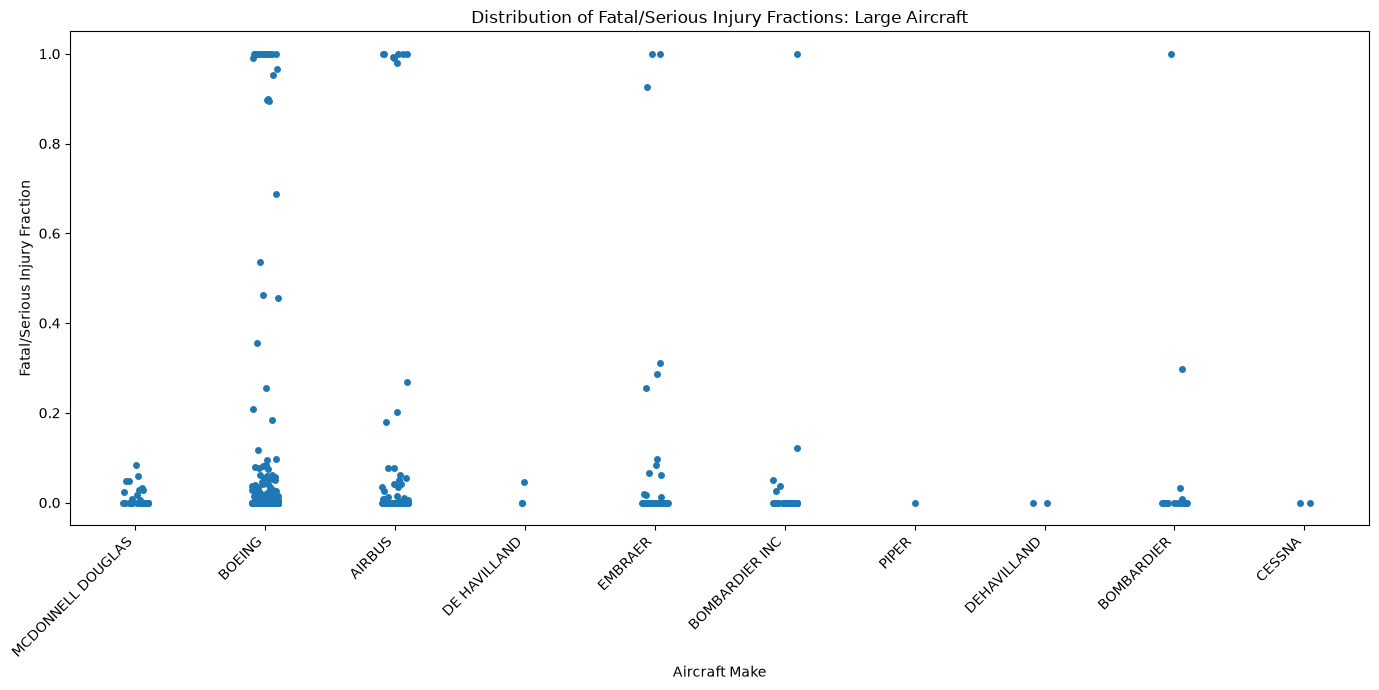

In [11]:
# Step 2: Create the strip plot
# Filter records for the 10 selected large-aircraft makes
large_plot_data = df[
    (df['Aircraft.Size'] == 'Large') &
    (df['Make'].isin(top_10_large_makes.index))
].dropna(subset=['Make', 'Fatal.Serious.Fraction'])

# Create the strip plot
plt.figure(figsize=(14, 7))

sns.stripplot(
    data=large_plot_data,
    x='Make',
    y='Fatal.Serious.Fraction',
    jitter=True
)

plt.title('Distribution of Fatal/Serious Injury Fractions: Large Aircraft')
plt.xlabel('Aircraft Make')
plt.ylabel('Fatal/Serious Injury Fraction')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

In [12]:
# Calculate the mean aircraft destruction rate by make and aircraft size
# 1 means the aircraft was destroyed; 0 means it was not destroyed
# The mean shows the percentage of accident records where the aircraft was destroyed.
make_destruction_rates = (
    df.dropna(subset=['Aircraft.Size', 'Make', 'Aircraft.Destroyed'])
    .groupby(['Aircraft.Size', 'Make'])['Aircraft.Destroyed']
    .mean()
    .reset_index()
)

# Display the destruction rates
make_destruction_rates.head()

,Aircraft.Size,Make,Aircraft.Destroyed
0,Large,AIRBUS,0.160000
1,Large,BEECH,1.000000
2,Large,BOEING,0.084034
3,Large,BOMBARDIER,0.062500
4,Large,BOMBARDIER INC,0.037037


In [13]:
# Sort destruction rates from lowest to highest within each aircraft size
top_15_destruction = (
    make_destruction_rates
    .sort_values('Aircraft.Destroyed')
    .groupby('Aircraft.Size')
    .head(15)
)

# Display the 15 makes with the lowest destruction rates in each group
top_15_destruction

,Aircraft.Size,Make,Aircraft.Destroyed
6,Large,DEHAVILLAND,0.000000
5,Large,DE HAVILLAND,0.000000
9,Large,RAYTHEON AIRCRAFT COMPANY,0.000000
34,Small,GRUMMAN ACFT ENG COR-SCHWEIZER,0.017241
35,Small,LUSCOMBE,0.017857
44,Small,STINSON,0.017857
45,Small,TAYLORCRAFT,0.027397
20,Small,BELLANCA,0.034091
4,Large,BOMBARDIER INC,0.037037
15,Small,AMERICAN CHAMPION AIRCRAFT,0.040000


In [15]:
# Convert destruction fractions to percentages
top_15_destruction['Destruction.Percentage'] = (
    top_15_destruction['Aircraft.Destroyed'] * 100
)

# Display the selected makes and their destruction rates
top_15_destruction[
    ['Aircraft.Size', 'Make', 'Destruction.Percentage']
]

,Aircraft.Size,Make,Destruction.Percentage
6,Large,DEHAVILLAND,0.000000
5,Large,DE HAVILLAND,0.000000
9,Large,RAYTHEON AIRCRAFT COMPANY,0.000000
34,Small,GRUMMAN ACFT ENG COR-SCHWEIZER,1.724138
35,Small,LUSCOMBE,1.785714
44,Small,STINSON,1.785714
45,Small,TAYLORCRAFT,2.739726
20,Small,BELLANCA,3.409091
4,Large,BOMBARDIER INC,3.703704
15,Small,AMERICAN CHAMPION AIRCRAFT,4.000000


#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

The summary statistics and plots help show differences in aircraft accident outcomes across different makes. Makes with a higher destroyed fraction may be associated with more severe accident damage, while those with a higher fraction of fatally or seriously injured people may have more serious safety outcomes.
Aircraft size comparison: 
Among the selected makes, large aircraft generally had lower mean fatal/serious injury fractions than small aircraft. 
However, large aircraft showed some higher destruction rates, such as Airbus at 16%, while small aircraft makes such as GRUMMAN recorded a low destruction rate of 1.72%. 
This suggests that lower injury fractions do not always correspond to lower destruction rates.

Recommendations: 
Prioritise aircraft makes with both low fatal/serious injury fractions and low destruction rates. 
Evaluate makes with conflicting results individually. 
Beech's 100% destruction rate is based on only two records and should not be treated as reliable evidence of poor safety. 
These findings compare accident outcomes and do not establish which aircraft size is safer overall.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

In [17]:
# Step 1: Prepare and calculate mean injury fractions
# Keep records with the required information
plane_data = df.dropna(
    subset=[
        'Aircraft.Size',
        'Aircraft.Type',
        'Fatal.Serious.Fraction'
    ]
).copy()

# Count records for each aircraft size and type
plane_type_counts = (
    plane_data
    .groupby(['Aircraft.Size', 'Aircraft.Type'])
    .size()
    .reset_index(name='Record.Count')
)

# Keep aircraft types with at least 10 records
eligible_plane_types = plane_type_counts[
    plane_type_counts['Record.Count'] >= 10
]

# Calculate mean injury fractions for eligible aircraft types
plane_type_rates = (
    plane_data
    .merge(
        eligible_plane_types[['Aircraft.Size', 'Aircraft.Type']],
        on=['Aircraft.Size', 'Aircraft.Type'],
        how='inner'
    )
    .groupby(['Aircraft.Size', 'Aircraft.Type'])['Fatal.Serious.Fraction']
    .mean()
    .reset_index()
)

# Display large aircraft first, followed by small aircraft
plane_type_rates['Aircraft.Size'] = pd.Categorical(
    plane_type_rates['Aircraft.Size'],
    categories=['Large', 'Small'],
    ordered=True
)

plane_type_rates = plane_type_rates.sort_values(
    ['Aircraft.Size', 'Fatal.Serious.Fraction']
)

# Display the results
plane_type_rates.head()

,Aircraft.Size,Aircraft.Type,Fatal.Serious.Fraction
9,Large,BOEING 777,0.000589
7,Large,BOEING 757,0.001560
10,Large,BOEING 787,0.003058
5,Large,BOEING 737-7H4,0.003537
11,Large,BOMBARDIER INC CL-600-2B19,0.004136


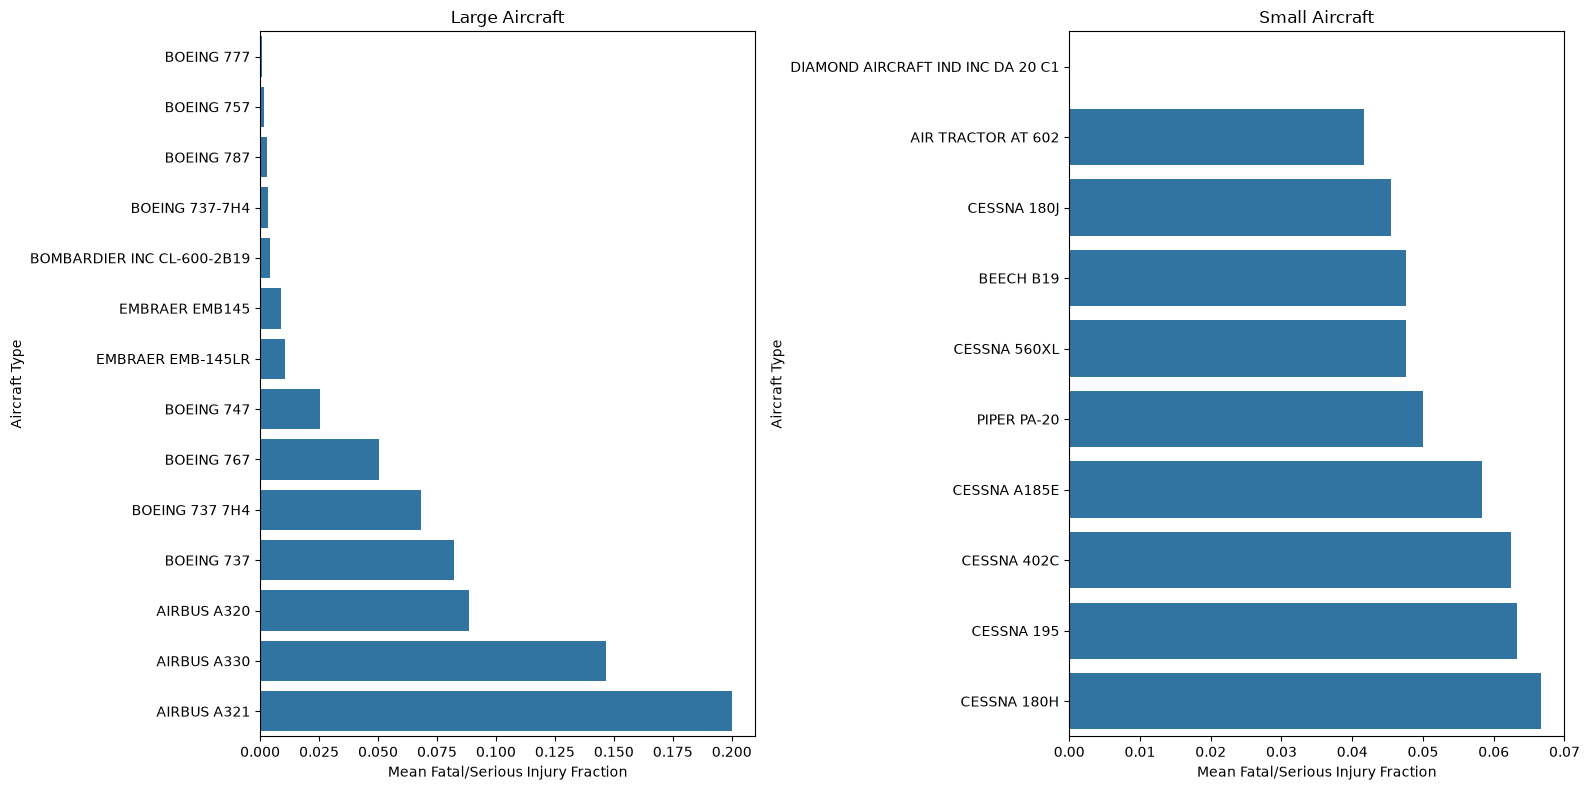

In [19]:
# Step 2: Plot mean injury functions
# Create separate plots for large and small aircraft
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

for ax, size in zip(axes, ['Large', 'Small']):
    plot_data = plane_type_rates[
        plane_type_rates['Aircraft.Size'] == size
    ].sort_values('Fatal.Serious.Fraction')

    # Show the 10 aircraft types with the lowest mean injury fractions
    if size == 'Small':
        plot_data = plot_data.head(10)

    sns.barplot(
        data=plot_data,
        x='Fatal.Serious.Fraction',
        y='Aircraft.Type',
        ax=ax
    )

    ax.set_title(f'{size} Aircraft')
    ax.set_xlabel('Mean Fatal/Serious Injury Fraction')
    ax.set_ylabel('Aircraft Type')

plt.tight_layout()
plt.show()

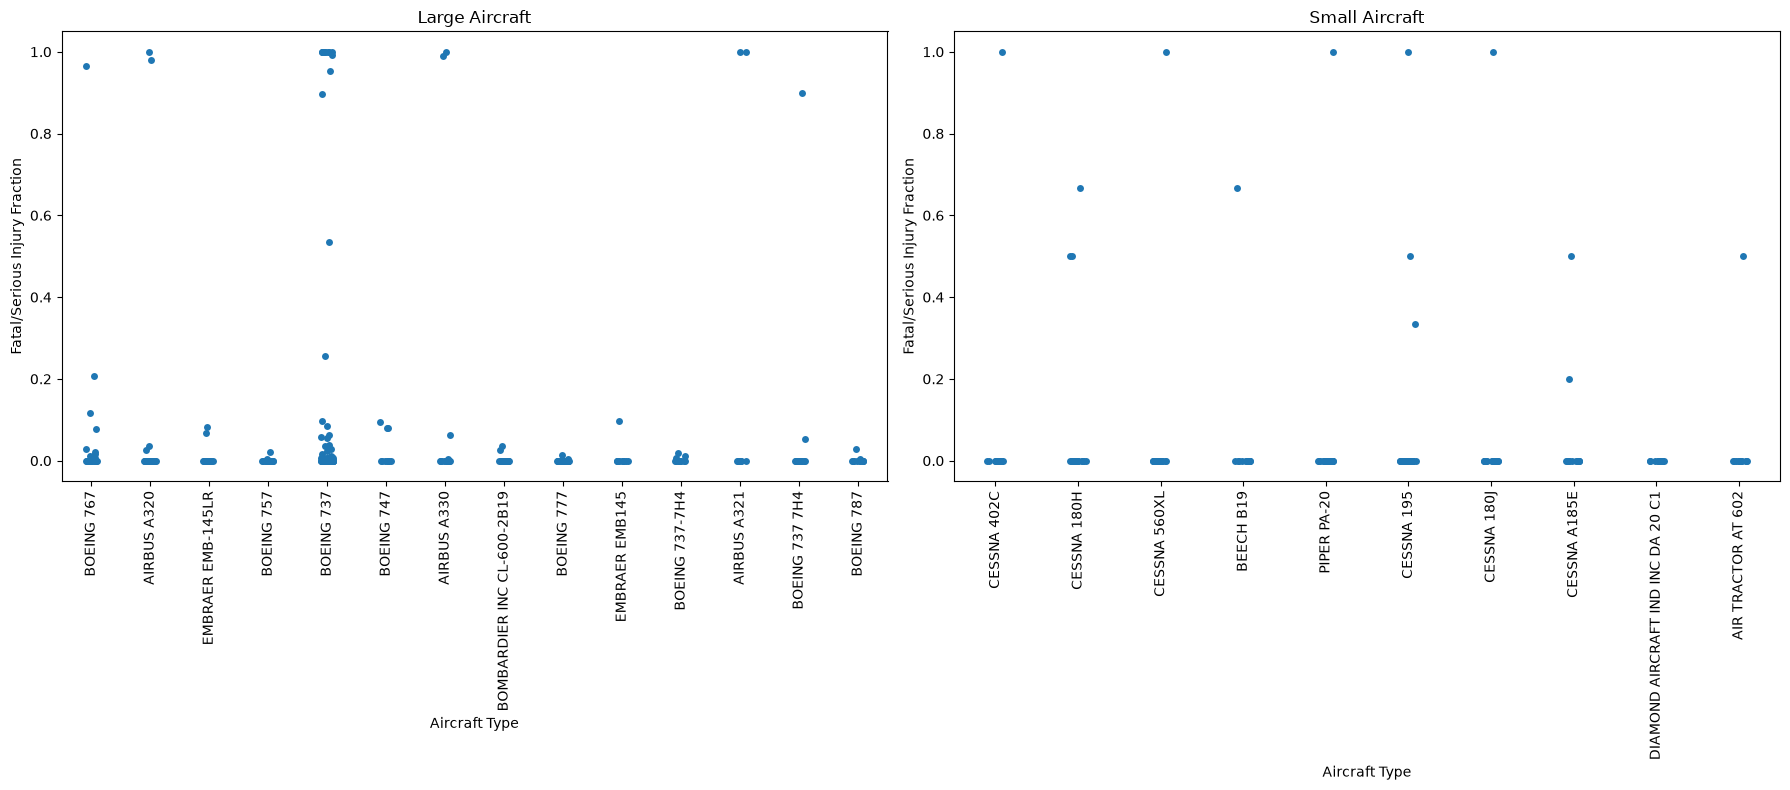

In [20]:
# Step 3: Plot the distribution of injury fractions

# Select eligible large aircraft types
large_types = plane_type_rates[
    plane_type_rates['Aircraft.Size'] == 'Large'
]['Aircraft.Type']

# Select the 10 small aircraft types with the lowest mean injury fractions
small_types = plane_type_rates[
    plane_type_rates['Aircraft.Size'] == 'Small'
].head(10)['Aircraft.Type']

# Filter the accident records for the selected aircraft types
distribution_data = plane_data[
    (
        (plane_data['Aircraft.Size'] == 'Large') &
        (plane_data['Aircraft.Type'].isin(large_types))
    ) |
    (
        (plane_data['Aircraft.Size'] == 'Small') &
        (plane_data['Aircraft.Type'].isin(small_types))
    )
].copy()

# Create separate distribution plots
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

for ax, size in zip(axes, ['Large', 'Small']):
    plot_data = distribution_data[
        distribution_data['Aircraft.Size'] == size
    ]

    sns.stripplot(
        data=plot_data,
        x='Aircraft.Type',
        y='Fatal.Serious.Fraction',
        jitter=True,
        ax=ax
    )

    ax.set_title(f'{size} Aircraft')
    ax.set_xlabel('Aircraft Type')
    ax.set_ylabel('Fatal/Serious Injury Fraction')
    ax.tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

In [22]:

# Calculate mean injury fraction for each small-aircraft make
small_make_rates = (
    df[df['Aircraft.Size'] == 'Small']
    .dropna(subset=['Make', 'Fatal.Serious.Fraction'])
    .groupby('Make')['Fatal.Serious.Fraction']
    .mean()
    .sort_values()
)

# Select the 10 makes with the lowest mean injury fractions
top_10_small_makes = small_make_rates.head(10)

# Display the selected makes and their mean injury fractions
top_10_small_makes

Make
BOMBARDIER INC                    0.100000
BOMBARDIER                        0.103846
MCDONNELL DOUGLAS                 0.121753
BOEING                            0.156968
AVIAT AIRCRAFT INC                0.164474
MAULE                             0.192593
GRUMMAN ACFT ENG COR-SCHWEIZER    0.206897
DIAMOND AIRCRAFT IND INC          0.222973
DEHAVILLAND                       0.234170
ROCKWELL INTERNATIONAL            0.236111
Name: Fatal.Serious.Fraction, dtype: float64

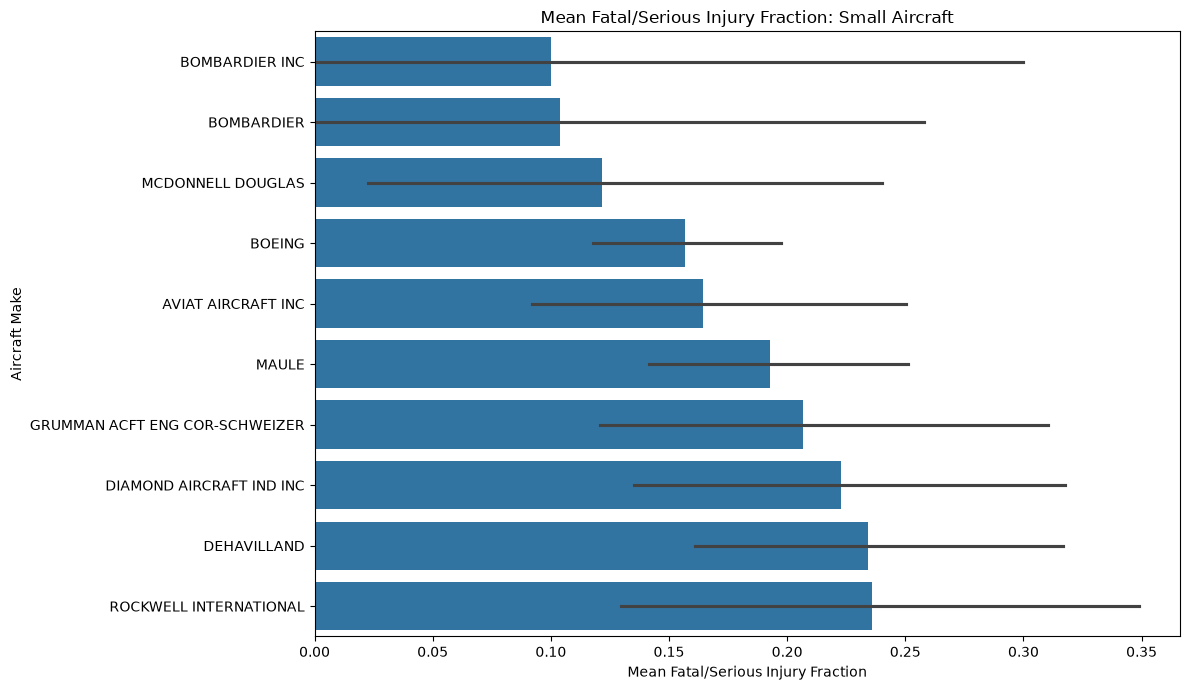

In [23]:
# Plot the mean fatal/serious injury fractions for the 10 selected small-aircraft makes
# Select accident records for the 10 small-aircraft makes
small_make_plot = df[
    (df['Aircraft.Size'] == 'Small') &
    (df['Make'].isin(top_10_small_makes.index))
].dropna(subset=['Make', 'Fatal.Serious.Fraction'])

# Plot the mean injury fraction for each make
plt.figure(figsize=(12, 7))

sns.barplot(
    data=small_make_plot,
    x='Fatal.Serious.Fraction',
    y='Make',
    order=top_10_small_makes.index
)

plt.title('Mean Fatal/Serious Injury Fraction: Small Aircraft')
plt.xlabel('Mean Fatal/Serious Injury Fraction')
plt.ylabel('Aircraft Make')

plt.tight_layout()
plt.show()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

We can see large airplane models generally showed lower fatal/serious injury fractions than small airplane models in the accident records analysed. 
This suggests that occupants involved in accidents involving the selected large models were less likely to sustain fatal or serious injuries as a proportion of total occupants. 

Small aircraft showed higher injury fractions overall.
However, some selected makes, such as BOMBARDIER INC and BOMBARDIER, recorded relatively low mean fractions. 
Injury vary by aircraft make and make

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

In [24]:
## 1. Weather Condition
# Step 1:Summarize aircraft damage and injuries by weather
# Group accident records by weather condition
weather_summary = (
    df.dropna(subset=['Weather.Condition'])
    .groupby('Weather.Condition')
    .agg(
        Accident_Count=('Event.Id', 'count'),
        Destruction_Rate=('Aircraft.Destroyed', 'mean'),
        Mean_Injury_Fraction=('Fatal.Serious.Fraction', 'mean')
    )
    .reset_index()
)

# Convert rates to percentages
weather_summary['Destruction_Percentage'] = (
    weather_summary['Destruction_Rate'] * 100
)

weather_summary['Injury_Percentage'] = (
    weather_summary['Mean_Injury_Fraction'] * 100
)

# Display the results
weather_summary.sort_values(
    'Accident_Count',
    ascending=False
)

,Weather.Condition,Accident_Count,Destruction_Rate,Mean_Injury_Fraction,Destruction_Percentage,Injury_Percentage
1,VMC,14274,0.071807,0.262643,7.180699,26.264339
0,IMC,904,0.366822,0.647654,36.682243,64.765393


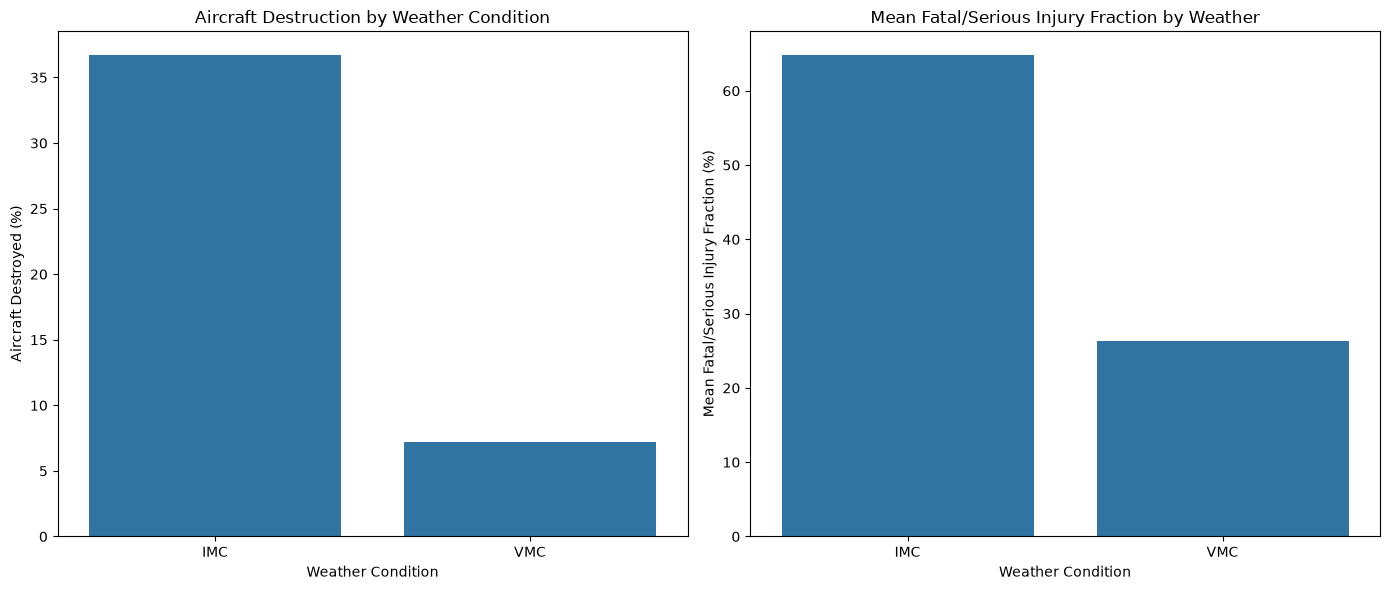

In [25]:
# Step 2: Visualise the results
# Create two plots to compare weather conditions
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot aircraft destruction rates
sns.barplot(
    data=weather_summary,
    x='Weather.Condition',
    y='Destruction_Percentage',
    ax=axes[0]
)

axes[0].set_title('Aircraft Destruction by Weather Condition')
axes[0].set_xlabel('Weather Condition')
axes[0].set_ylabel('Aircraft Destroyed (%)')

# Plot mean injury fractions
sns.barplot(
    data=weather_summary,
    x='Weather.Condition',
    y='Injury_Percentage',
    ax=axes[1]
)

axes[1].set_title('Mean Fatal/Serious Injury Fraction by Weather')
axes[1].set_xlabel('Weather Condition')
axes[1].set_ylabel('Mean Fatal/Serious Injury Fraction (%)')

plt.tight_layout()
plt.show()


Weather conditions were strongly associated with accident outcomes in the dataset. 
Accidents recorded under IMC had higher aircraft destruction rates and mean fatal/serious injury fractions than those under VMC. 

This suggests that accidents occurring in instrument meteorological conditions tended to have more severe outcomes. 
However, these results describe recorded accidents and do not establish that weather alone caused the differences.


In [26]:
## 2. Phase of flights
# Summarise aircraft damage and injuries by phase of flight
phase_summary = (
    df.dropna(subset=['Broad.phase.of.flight'])
    .groupby('Broad.phase.of.flight')
    .agg(
        Accident_Count=('Event.Id', 'count'),
        Destruction_Rate=('Aircraft.Destroyed', 'mean'),
        Mean_Injury_Fraction=('Fatal.Serious.Fraction', 'mean')
    )
    .reset_index()
)

# Convert rates to percentages
phase_summary['Destruction_Percentage'] = (
    phase_summary['Destruction_Rate'] * 100
)

phase_summary['Injury_Percentage'] = (
    phase_summary['Mean_Injury_Fraction'] * 100
)

# Display phases with the most recorded accidents first
phase_summary.sort_values(
    'Accident_Count',
    ascending=False
)

,Broad.phase.of.flight,Accident_Count,Destruction_Rate,Mean_Injury_Fraction,Destruction_Percentage,Injury_Percentage
5,LANDING,1107,0.012647,0.166667,1.264679,16.666667
9,TAKEOFF,422,0.102138,0.530497,10.213777,53.049728
2,CRUISE,237,0.134199,0.700000,13.419913,70.000000
0,APPROACH,207,0.107317,0.727617,10.731707,72.761708
6,MANEUVERING,123,0.268293,0.750000,26.829268,75.000000
10,TAXI,97,0.010870,NaN,1.086957,NaN
4,GO-AROUND,81,0.061728,0.000000,6.172840,0.000000
3,DESCENT,59,0.145455,0.419591,14.545455,41.959064
1,CLIMB,51,0.306122,0.600000,30.612245,60.000000
8,STANDING,33,0.037037,NaN,3.703704,NaN


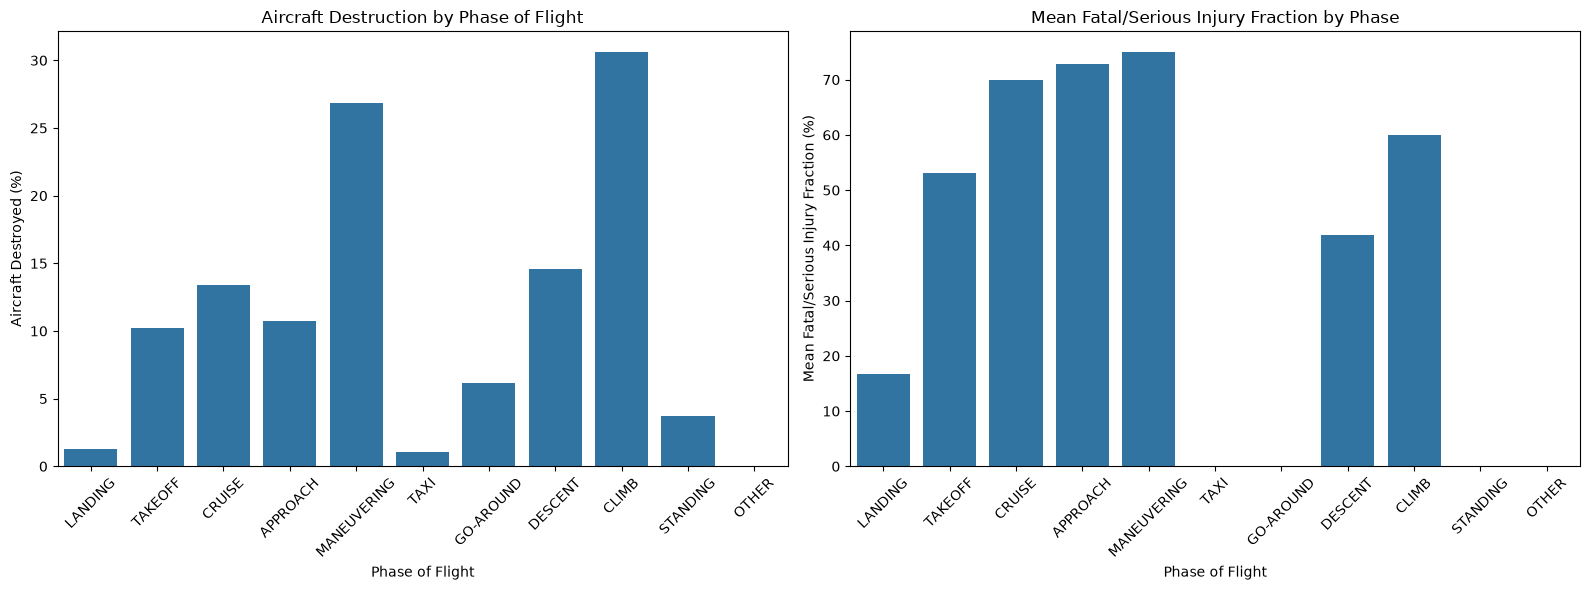

In [27]:
# Step 2: Visualise the results
# Sort flight phases by the number of recorded accidents
phase_plot_data = phase_summary.sort_values(
    'Accident_Count',
    ascending=False
)

# Create two plots side by side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot aircraft destruction percentages
sns.barplot(
    data=phase_plot_data,
    x='Broad.phase.of.flight',
    y='Destruction_Percentage',
    ax=axes[0]
)

axes[0].set_title('Aircraft Destruction by Phase of Flight')
axes[0].set_xlabel('Phase of Flight')
axes[0].set_ylabel('Aircraft Destroyed (%)')
axes[0].tick_params(axis='x', rotation=45)

# Plot mean fatal/serious injury fractions
sns.barplot(
    data=phase_plot_data,
    x='Broad.phase.of.flight',
    y='Injury_Percentage',
    ax=axes[1]
)

axes[1].set_title('Mean Fatal/Serious Injury Fraction by Phase')
axes[1].set_xlabel('Phase of Flight')
axes[1].set_ylabel('Mean Fatal/Serious Injury Fraction (%)')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

INTERPRETATION: Phase of Flight

The results show that the severity of accidents varied depending on the phase of flight.

- Landing had the highest number of accidents (1,107), but only 1.26% involved destroyed aircraft.
- Climb had the highest aircraft destruction rate at 30.61%.
- Maneuvering had the highest mean fatal/serious injury fraction at 75%.
- Approach and cruise also had high injury fractions.

These findings suggest that some flight phases are associated with more severe accident outcomes than others. 
However, the results describe recorded accidents only and do not prove that a particular flight phase causes more severe accidents.
